# Reject Option Classification on Adult, German Credit and COMPAS

In this notebook, I applies **Reject Option Classification (ROC)** by Kamiran, Karim & Zhang via AIF360.

ROC is *post-processing* fair algorithm. Given a classifier score, instances in the *critical region* — where the classifier is least sure — are relabelled: favourable labels to the **unprivileged** group and vice versa for the **privileged**. Outside of this range, the classifier's decision stands. 

Conventionally, the critical region is determined after consulting field experts, however, for this implementation, a grid search is run in `ROC_threshold_search.ipynb` to optimize balanced accuracy and the results are loaded into this notebook. 

The progression is as following:
| Section | Content |
|---|---|
| 0 | Setting up|
| 1 | Original DP_Diff, DIR, consistency|
| 2 | Stratified train / validation / test split |
| 3 | Reject Option Classification on Logistic Regression|
| 4 | Fairness + accuracy, balanced accuracy, F1 on the **test set** |
| 5 | Before vs after; discussion |

### Install

AIF360 0.6.1 breaks under pandas 3 (its default string dtype breaks `StandardDataset`), so pandas is pinned to 2.x. 

In [58]:
%pip install -q "aif360==0.6.1" "pandas>=2.2,<3" scikit-learn matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [59]:
# Import necessary libraries
import json
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from aif360.algorithms.postprocessing import RejectOptionClassification
from aif360.datasets import AdultDataset, CompasDataset, GermanDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Check pandas version
if int(pd.__version__.split(".")[0]) >= 3:
    raise RuntimeError(
        f"pandas {pd.__version__} is loaded, but AIF360 0.6.1 only works with pandas 2.x. "
        "The %pip cell above installs pandas 2.x: restart the kernel and run all cells again "
        "(or select the project's .venv as the kernel).")
# Disable logging messages for cleaner output
logging.disable(logging.WARNING)
logging.disable(logging.NOTSET)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

SEED = 0
TEST_SIZE = 0.30
VAL_SIZE = 0.20
K_NEIGHBORS = 5

## 0. Data

Loaded with AIF360's built-in loaders (`aif360.datasets`):

| Loader | Original source |
|---|---|
| `AdultDataset` | [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult) |
| `GermanDataset` | [UCI Statlog German Credit, id 144](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data) |
| `CompasDataset` | ProPublica [`compas-analysis`](https://github.com/propublica/compas-analysis) |

### 0.1 Pre-processing and protected attributes

Beyond AIF360's defaults, all features are min-max scaled to [0, 1] so that `consistency()` (k-NN on raw features) is not dominated by `capital-gain` or `credit_amount`.

| Dataset | AIF360 default pre-processing | Favourable label | Protected attribute | Privileged | Unprivileged |
|---|---|---|---|---|---|
| Adult | `adult.data` + `adult.test` (48,842 rows); rows with missing values (`?`) and `fnlwgt` dropped | income > \$50K | sex | Male | Female |
| German | all 1,000 rows; `personal_status` replaced by a derived `sex` column | good credit risk | age | > 25 years | ≤ 25 years (Kamiran & Calders' split) |
| COMPAS | ProPublica filter (screening within 30 days of arrest, valid recidivism flag, no ordinary-traffic charges); rows with missing values dropped | **no** recidivism within 2 years | race | Caucasian | non-Caucasian |

In [60]:
def load_adult():
    return AdultDataset(
        protected_attribute_names=["sex"], privileged_classes=[["Male"]],
        categorical_features=["workclass", "education", "marital-status", "occupation",
                              "relationship", "native-country", "race"],        
    )


def load_german():
    return GermanDataset(
        protected_attribute_names=["age"], privileged_classes=[lambda age: age > 25],
        categorical_features=["status", "credit_history", "purpose", "savings", "employment",
                              "other_debtors", "property", "installment_plans", "housing",
                              "skill_level", "telephone", "foreign_worker", "sex"], 
    )


def load_compas():
    return CompasDataset(
        protected_attribute_names=["race"], privileged_classes=[["Caucasian"]],
        categorical_features=["age_cat", "c_charge_degree", "c_charge_desc", "sex"], 
    )


DATASETS = {
    "Adult":  dict(loader=load_adult,  attr="sex",  priv="Male",      unpriv="Female",        fav="income > $50K"),
    "German": dict(loader=load_german, attr="age",  priv="age > 25",  unpriv="age ≤ 25",      fav="good credit risk"),
    "COMPAS": dict(loader=load_compas, attr="race", priv="Caucasian", unpriv="non-Caucasian", fav="no recidivism (2 y)"),
}


def groups(name):
    """AIF360 group definitions: protected attribute 1 = privileged, 0 = unprivileged."""
    a = DATASETS[name]["attr"]
    return dict(unprivileged_groups=[{a: 0}], privileged_groups=[{a: 1}])


datasets, overview = {}, []
for name, cfg in DATASETS.items():
    ds = cfg["loader"]()
    ds.features = MinMaxScaler().fit_transform(ds.features) #scale features to [0, 1] for k-NN
    datasets[name] = ds
    prot = ds.protected_attributes[:, 0]
    overview.append({
        "dataset": name, "rows": ds.features.shape[0],
        "favourable label": cfg["fav"],
        "label code (fav/unfav)": f"{ds.favorable_label:g} / {ds.unfavorable_label:g}",
        "protected": cfg["attr"], 
        "% unprivileged": 100 * (prot == 0).mean(),
        "% favourable": 100 * (ds.labels.ravel() == ds.favorable_label).mean(),
    })
pd.DataFrame(overview).set_index("dataset").round(1)

,rows,favourable label,label code (fav/unfav),protected,% unprivileged,% favourable
dataset,,,,,,
Adult,45222,income > $50K,1 / 0,sex,32.5,24.8
German,1000,good credit risk,1 / 2,age,19.0,70.0
COMPAS,6167,no recidivism (2 y),0 / 1,race,65.9,54.5


In [61]:
def fairness(name, ds):
    """Group and individual fairness of the labels stored in `ds`."""
    m = BinaryLabelDatasetMetric(ds, **groups(name))
    return {
        "P(fav|unpriv)": m.base_rate(privileged=False),
        "P(fav|priv)": m.base_rate(privileged=True),
        "DP_Diff": m.statistical_parity_difference(),
        "DIR": m.disparate_impact(),
        "Consistency": m.consistency(n_neighbors=K_NEIGHBORS)[0],
    }


def performance(name, ds_true, ds_pred):
    y, y_hat, fav = ds_true.labels.ravel(), ds_pred.labels.ravel(), ds_true.favorable_label
    return {
        "Accuracy": ClassificationMetric(ds_true, ds_pred, **groups(name)).accuracy(),
        "Balanced acc.": balanced_accuracy_score(y, y_hat),
        "F1": f1_score(y, y_hat, pos_label=fav),
    }

## 1. Fairness of the original labels

In [62]:
step1 = pd.DataFrame({
    name: fairness(name, ds) for name, ds in datasets.items()
}).T
step1.index.name = "dataset"
step1

,P(fav|unpriv),P(fav|priv),DP_Diff,DIR,Consistency
dataset,,,,,
Adult,0.114,0.312,-0.199,0.363,0.827
German,0.579,0.728,-0.149,0.795,0.746
COMPAS,0.511,0.609,-0.097,0.840,0.671


All three label sets already favour the privileged group:

* **Adult**: 11.4 % of women vs 31.2 % of men earn > \$50K. DP_Diff −0.199, DIR 0.36 — far below the four-fifths threshold.
* **German**: 57.9 % of applicants ≤ 25 vs 72.8 % of older ones are good risks. DP_Diff −0.149, DIR 0.80 — right at the threshold.
* **COMPAS**: 51.1 % of non-Caucasian vs 60.9 % of Caucasian defendants did not reoffend within two years. DP_Diff −0.097, DIR 0.84.
* **Consistency** is moderate: similar individuals often have different outcomes, especially in COMPAS.

## 2. Stratified train / validation / test split

ROC must be fitted on predictions for data the classifier never saw, so rows are split to the ratio of 50:20:30 for train : validation : test. Both splits are stratified on label × protected group (four strata), preserving the favourable rate and group composition. 

In [63]:
def stratified_split(ds, seed):
    """Train / validation / test = 50 / 20 / 30 % of rows, stratified on label x protected group."""
    strata = ds.labels.ravel().astype(int) * 2 + ds.protected_attributes[:, 0].astype(int)
    idx = np.arange(len(strata))
    rest, test = train_test_split(idx, test_size=TEST_SIZE, stratify=strata, random_state=seed)
    train, val = train_test_split(rest, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                  stratify=strata[rest], random_state=seed)
    return ds.subset(train), ds.subset(val), ds.subset(test)


split_rows = []
for name, ds in datasets.items():
    for part, d in zip(["all", "train", "validation", "test"], [ds, *stratified_split(ds, SEED)]):
        split_rows.append({
            "dataset": name, "split": part, "rows": d.features.shape[0],
            "% favourable": 100 * (d.labels.ravel() == d.favorable_label).mean(),
            "% unprivileged": 100 * (d.protected_attributes[:, 0] == 0).mean(),
            "% fav | unpriv": 100 * (d.labels.ravel()[d.protected_attributes[:, 0] == 0] == d.favorable_label).mean(),
            "% fav | priv": 100 * (d.labels.ravel()[d.protected_attributes[:, 0] == 1] == d.favorable_label).mean(),
        })
pd.DataFrame(split_rows).set_index(["dataset", "split"]).round(1)

rows  % favourable  % unprivileged  % fav | unpriv  % fav | priv
dataset split                                                                        
Adult   all         45222          24.8            32.5            11.4          31.2
        train       22610          24.8            32.5            11.4          31.2
        validation   9045          24.8            32.5            11.4          31.2
        test        13567          24.8            32.5            11.4          31.3
German  all          1000          70.0            19.0            57.9          72.8
        train         499          69.9            19.0            57.9          72.8
        validation    201          70.1            18.9            57.9          73.0
        test          300          70.0            19.0            57.9          72.8
COMPAS  all          6167          54.5            65.9            51.1          60.9
        train        3082          54.4            66.0            51.2          60.8
        validation   1234          54.5            66.0            51.1          61.0
        test         1851          54.5            65.9            51.1          60.9

## 3. Reject Option Classification

Ideally, domain experts would set the decision threshold and ROC's margin alongside the fairness target. Lacking such input, both come from **`ROC_threshold_search.ipynb`**: a validation-set grid search maximising balanced accuracy, with $|\text{DP\_Diff}| \le 0.05$ as ROC's constraint. Its result, `results/roc_thresholds.json`, is required so the next cell runs the search notebook.

Per dataset, the next cell follows the process of:

1. **Classify** Logistic regression on standardised train features.
2. **Baseline** applies one threshold for every dataset: favourable iff $s(x) > t_\text{base}$.
3. **ROC** Inside $(\theta - m, \theta + m]$: unprivileged gets favourable label, privileged gets unfavourable labels; outside, favourable iff $s(x) > \theta$. Equivalently, group thresholds $\theta - m$ for the unprivileged and $\theta + m$ for the privileged.
4. **Evaluate** on the test set

In [64]:
# Run the threshold search notebook
import sys
!"{sys.executable}" -m jupyter nbconvert --to notebook --execute --inplace ROC_threshold_search.ipynb

[NbConvertApp] Converting notebook ROC_threshold_search.ipynb to notebook
[NbConvertApp] Writing 15529 bytes to ROC_threshold_search.ipynb


In [65]:
# Baseline threshold, θ and m
search = json.loads((RESULTS / "roc_thresholds.json").read_text())
same_split = all(search["settings"][k] == v for k, v in dict(SEED=SEED, TEST_SIZE=TEST_SIZE, VAL_SIZE=VAL_SIZE).items())
THRESHOLDS = search["thresholds"]


def scored(ds, clf, scaler):
    """Copy of `ds` whose .scores hold the classifier's P(favourable | x)."""
    out = ds.copy(deepcopy=True)
    fav_col = list(clf.classes_).index(ds.favorable_label)
    out.scores = clf.predict_proba(scaler.transform(ds.features))[:, [fav_col]]
    return out


def thresholded(ds_scored, t):
    """Copy with labels = favourable iff score > t (same convention as AIF360's ROC)."""
    out = ds_scored.copy(deepcopy=True)
    out.labels = np.where(ds_scored.scores > t, ds_scored.favorable_label, ds_scored.unfavorable_label)
    return out


def run_pipeline(name, ds):
    train, _, test = stratified_split(ds, SEED)      # the validation set was used by the threshold search
    p = THRESHOLDS[name]

    # 1) Logistic regression classifier
    std = StandardScaler().fit(train.features)
    clf = LogisticRegression(max_iter=5000).fit(std.transform(train.features), train.labels.ravel())
    test_s = scored(test, clf, std)

    # 2) baseline: one threshold for every dataset
    test_base = thresholded(test_s, p["baseline threshold"])

    # 3) ROC with the searched θ and m
    roc = RejectOptionClassification(**groups(name))
    roc.classification_threshold, roc.ROC_margin = p["ROC threshold θ"], p["ROC margin m"]
    test_roc = roc.predict(test_s)

    results = {
        "Original labels (test)": fairness(name, test),
        "LR, no mitigation": {**fairness(name, test_base), **performance(name, test, test_base)},
        "LR + ROC": {**fairness(name, test_roc), **performance(name, test, test_roc)},
    }
    s = test_s.scores.ravel()
    theta, margin = roc.classification_threshold, roc.ROC_margin
    critical = (s > theta - margin) & (s <= theta + margin)
    unpriv = test.protected_attributes[:, 0] == 0
    base_fav = test_base.labels.ravel() == test.favorable_label
    roc_fav = test_roc.labels.ravel() == test.favorable_label
    info = {
        "baseline threshold": p["baseline threshold"],
        "ROC threshold θ": theta,
        "ROC margin m": margin,
        "critical region": f"({theta - margin:.3f}, {theta + margin:.3f}]",
        "constraint met": p["constraint met"],
        "unprivileged rows in validation": p["unprivileged rows in validation"],
        "DP_Diff on validation (ROC)": p["DP_Diff on validation (ROC)"],
        "% test in critical region": 100 * critical.mean(),
        "test decisions changed vs baseline": int((base_fav != roc_fav).sum()),
        "  unprivileged: unfav → fav": int((unpriv & ~base_fav & roc_fav).sum()),
        "  unprivileged: fav → unfav": int((unpriv & base_fav & ~roc_fav).sum()),
        "  privileged: fav → unfav": int((~unpriv & base_fav & ~roc_fav).sum()),
        "  privileged: unfav → fav": int((~unpriv & ~base_fav & roc_fav).sum()),
    }
    return results, info


main_results, main_info = {}, {}
for name, ds in datasets.items():
    main_results[name], main_info[name] = run_pipeline(name, ds)

pd.DataFrame(main_info)

,Adult,German,COMPAS
baseline threshold,0.198,0.673,0.475
ROC threshold θ,0.188,0.752,0.535
ROC margin m,0.138,0.091,0.057
critical region,"(0.050, 0.326]","(0.661, 0.843]","(0.478, 0.592]"
constraint met,True,True,True
unprivileged rows in validation,2939,38,814
DP_Diff on validation (ROC),-0.047,0.014,0.025
% test in critical region,31.201,25.333,17.288
test decisions changed vs baseline,2067,66,108
unprivileged: unfav → fav,823,5,0


## 4. Results on the held-out test set

In [66]:
step4 = pd.concat(
    {name: pd.DataFrame(res).T for name, res in main_results.items()}, names=["dataset", "labels evaluated"]
)
step4 = step4[["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc.", "F1", "P(fav|unpriv)", "P(fav|priv)"]]
step4.round(3).fillna("–")      # accuracy etc. are undefined for the ground-truth rows

DP_Diff    DIR  Consistency Accuracy Balanced acc.     F1  P(fav|unpriv)  P(fav|priv)
dataset labels evaluated                                                                                             
Adult   Original labels (test)   -0.199  0.364        0.824        –             –      –          0.114        0.313
        LR, no mitigation        -0.361  0.300        0.943    0.791         0.821  0.676          0.155        0.516
        LR + ROC                 -0.038  0.899        0.928     0.78         0.786  0.643          0.342        0.380
German  Original labels (test)   -0.149  0.795        0.705        –             –      –          0.579        0.728
        LR, no mitigation        -0.507  0.276        0.773    0.723         0.717  0.788          0.193        0.700
        LR + ROC                 -0.168  0.626        0.758    0.623         0.687  0.663          0.281        0.449
COMPAS  Original labels (test)   -0.097  0.840        0.670        –             –      –          0.511        0.609
        LR, no mitigation        -0.125  0.828        0.854    0.654         0.642  0.709          0.602        0.727
        LR + ROC                  0.037  1.065        0.836    0.651         0.644  0.691          0.599        0.563

## 5. Before vs after mitigation

In [67]:
compare_rows = []
for name in datasets:
    before = main_results[name]["LR, no mitigation"]
    after = main_results[name]["LR + ROC"]
    for metric in ["DP_Diff", "DIR", "Consistency"]:
        compare_rows.append({"dataset": name, "metric": metric,
                             "LR, no mitigation": before[metric],
                             " LR + ROC": after[metric]})
comparison = pd.DataFrame(compare_rows).set_index(["dataset", "metric"])
comparison.round(3)

LR, no mitigation   LR + ROC
dataset metric                                   
Adult   DP_Diff                 -0.361     -0.038
        DIR                      0.300      0.899
        Consistency              0.943      0.928
German  DP_Diff                 -0.507     -0.168
        DIR                      0.276      0.626
        Consistency              0.773      0.758
COMPAS  DP_Diff                 -0.125      0.037
        DIR                      0.828      1.065
        Consistency              0.854      0.836

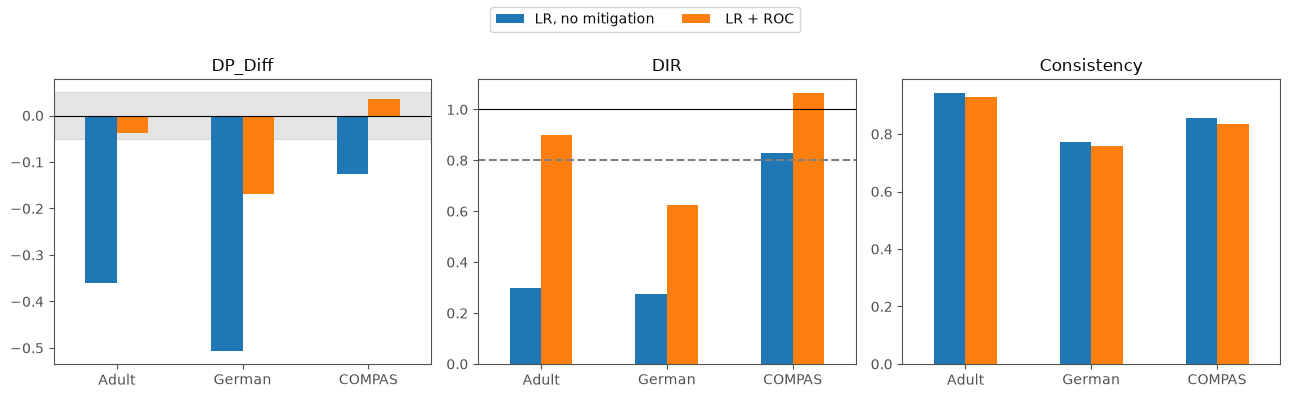

In [68]:
# One panel per fairness metric; bars = labels evaluated, grouped by dataset
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["DP_Diff", "DIR", "Consistency"]):
    comparison.xs(metric, level="metric").plot.bar(ax=ax, rot=0, legend=False, title=metric, xlabel="")

axes[0].axhline(0, color="black", lw=0.8)                                    # parity
axes[0].axhspan(-0.05, 0.05, color="grey", alpha=0.2, zorder=0)              # ROC target of +-0.05
axes[1].axhline(1, color="black", lw=0.8)                                    # parity
axes[1].axhline(0.8, color="grey", ls="--")                                  # four-fifths rule

fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

### 5.1 Discussion

**Group fairness** (DP_Diff / DIR):

| | LR, no mitigation | After: LR + ROC | Verdict |
|---|---|---|---|
| Adult |  −0.361 / 0.30 | −0.038 / 0.90 | Bias largely removed; DIR crosses the 0.8 threshold. |
| German |  −0.507 / 0.28 | −0.168 / 0.63 | ROC removes most of the classifier's bias, but ends worse than the original labels. |
| COMPAS | −0.125 / 0.83 | +0.037 / 1.07 | Bias removed, no measurable accuracy cost. |

1. **The classifier amplifies label bias. ROC removes most of the excess.** Unmitigated LR is less fair than its training labels on all three datasets: it turns weak associations into hard decisions, and the protected attribute and its proxies (relationship = "Husband", age category, priors count, …) predict well. ROC then brings DP_Diff much closer to zero.

2. **The constraint holds on validation, not necessarily on test.** Validation DP_Diff: Adult −0.047, German +0.014, COMPAS +0.025. On test it holds for Adult (−0.038) and COMPAS (+0.037), not German (−0.168). The reasons might be:
   * *Small validation groups.* Adult's validation set has 2,939 unprivileged rows; German's has 38 young applicants. There, DP_Diff's standard error alone is apprx. 0.09, wider than the error band, and θ, m are tuned to that noise.
   * *ROC targets the band's edge.* Less correction means higher balanced accuracy, so ROC picks the feasible point nearest the unconstrained classifier. Validation–test gap can then breach the band.

3. **Individual fairness slightly lowers after ROC.** ROC itself lowers consistency when compared to unmitigated logistic regression, since within the critical region it labels similar people differently by group. The cost is small because only near-boundary instances change — the usual tension between group and individual fairness.

4. **Predictive cost.**
   * **Adult**: balanced accuracy −3.5 pts, accuracy −1 pt.
   * **COMPAS**: less than -1pt for both balanced accuracy and accuracy. 
   * **German**: highest trade-off. accuracy −10 pts, balanced accuracy −3 pts